In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [ ]:
import pandas as pd
import os

DATA_DIR = "../data/raw/NIH_ChestXray14"

csv_path = os.path.join(DATA_DIR, "Data_Entry_2017_v2020.csv")

df = pd.read_csv(csv_path)

print("Number of images:", len(df))
print("Number of patients:", df["Patient ID"].nunique())
print()
print("Columns:")
print(df.columns.tolist())

Number of images: 112120
Number of patients: 30805

Columns:
['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Sex', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]']


In [3]:
df.head()

,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
0,00000001_000.png,Cardiomegaly,0,1,57,M,PA,2682,2749,0.143,0.143
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168
3,00000002_000.png,No Finding,0,2,80,M,PA,2500,2048,0.171,0.171
4,00000003_001.png,Hernia,0,3,74,F,PA,2500,2048,0.168,0.168


In [4]:
df["Finding Labels"].head(20)

0               Cardiomegaly
1     Cardiomegaly|Emphysema
2      Cardiomegaly|Effusion
3                 No Finding
4                     Hernia
5                     Hernia
6        Hernia|Infiltration
7                     Hernia
8                     Hernia
9                     Hernia
10                    Hernia
11                    Hernia
12               Mass|Nodule
13                No Finding
14                No Finding
15                No Finding
16                No Finding
17                No Finding
18                No Finding
19              Infiltration
Name: Finding Labels, dtype: str

In [5]:
from collections import Counter

counter = Counter()

for labels in df["Finding Labels"]:
    for label in labels.split("|"):
        counter[label] += 1

label_counts = pd.DataFrame(
    counter.items(),
    columns=["Disease", "Count"]
).sort_values("Count", ascending=False)

display(label_counts)

,Disease,Count
3,No Finding,60361
5,Infiltration,19894
2,Effusion,13317
8,Atelectasis,11559
7,Nodule,6331
6,Mass,5782
9,Pneumothorax,5302
14,Consolidation,4667
10,Pleural_Thickening,3385
0,Cardiomegaly,2776


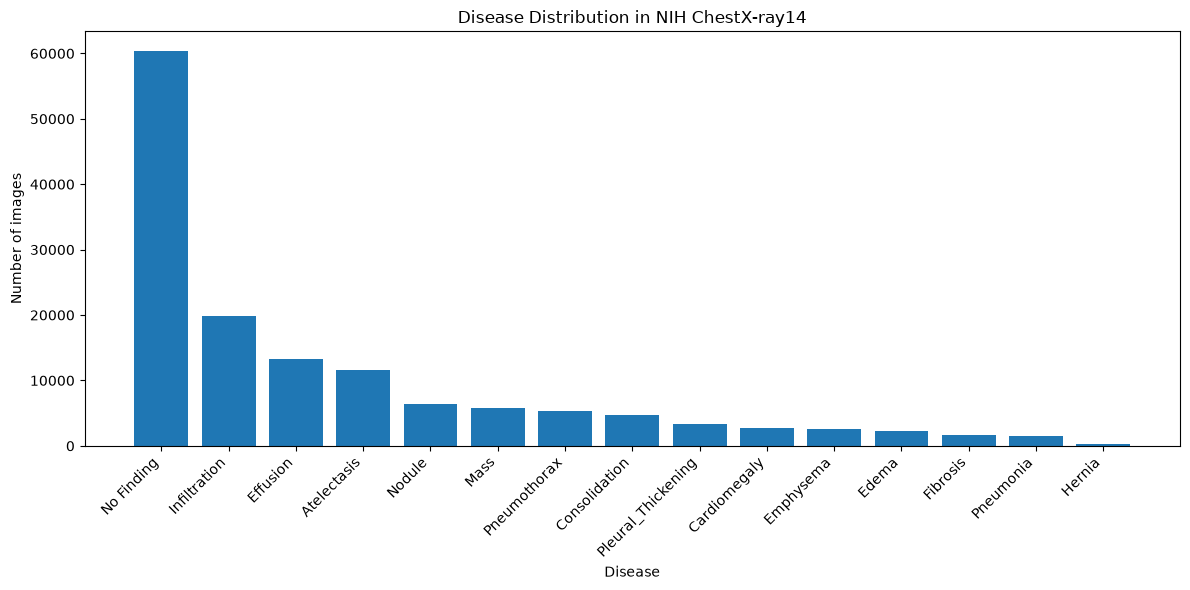

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    label_counts["Disease"],
    label_counts["Count"]
)

plt.xticks(rotation=45, ha="right")
plt.xlabel("Disease")
plt.ylabel("Number of images")
plt.title("Disease Distribution in NIH ChestX-ray14")
plt.tight_layout()
plt.show()

Decide the target diseases

In [7]:
TARGET_LABELS = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltration",
    "Pneumonia"
]

print("Target diseases:")
for i, label in enumerate(TARGET_LABELS, 1):
    print(i, label)

Target diseases:
1 Atelectasis
2 Cardiomegaly
3 Effusion
4 Infiltration
5 Pneumonia


Create the multilabel targets

In [8]:
for label in TARGET_LABELS:
    df[label] = df["Finding Labels"].apply(
        lambda x: 1 if label in x.split("|") else 0
    )

df[TARGET_LABELS].head()

,Atelectasis,Cardiomegaly,Effusion,Infiltration,Pneumonia
0,0,1,0,0,0
1,0,1,0,0,0
2,0,1,1,0,0
3,0,0,0,0,0
4,0,0,0,0,0


Check the target distribution

In [9]:
df[TARGET_LABELS].sum().sort_values(ascending=False)

Infiltration    19894
Effusion        13317
Atelectasis     11559
Cardiomegaly     2776
Pneumonia        1431
dtype: int64

In [10]:
df[TARGET_LABELS].mean() * 100

Atelectasis     10.309490
Cardiomegaly     2.475919
Effusion        11.877453
Infiltration    17.743489
Pneumonia        1.276311
dtype: float64

Check the patient information

In [13]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Sex', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]', 'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration', 'Pneumonia']


In [15]:
df[[
    "Patient ID",
    "Patient Age",
    "Patient Sex",
    "View Position"
]].head(10)

,Patient ID,Patient Age,Patient Sex,View Position
0,1,57,M,PA
1,1,58,M,PA
2,1,58,M,PA
3,2,80,M,PA
4,3,74,F,PA
5,3,75,F,PA
6,3,76,F,PA
7,3,77,F,PA
8,3,78,F,PA
9,3,79,F,PA


Clean the age column

In [16]:
print(df["Patient Age"].describe())

count    112120.000000
mean         46.626365
std          16.602680
min           0.000000
25%          34.000000
50%          49.000000
75%          59.000000
max          95.000000
Name: Patient Age, dtype: float64


In [17]:
print("Minimum age:", df["Patient Age"].min())
print("Maximum age:", df["Patient Age"].max())

Minimum age: 0
Maximum age: 95


In [18]:
df["Patient Age"] = pd.to_numeric(
    df["Patient Age"],
    errors="coerce"
)

In [19]:
print(df["Patient Age"].isna().sum())

0


Check gender and view position

In [21]:
print(df["Patient Sex"].value_counts(dropna=False))

Patient Sex
M    63340
F    48780
Name: count, dtype: int64


In [22]:
print(df["View Position"].value_counts(dropna=False))

View Position
PA    67310
AP    44810
Name: count, dtype: int64


Load the official test list

In [23]:
import os

DATA_DIR = "../data/raw/NIH_ChestXray14"

test_file = os.path.join(DATA_DIR, "test_list.txt")

with open(test_file, "r") as f:
    test_images = [line.strip() for line in f.readlines()]

print("Number of test images:", len(test_images))
print("First 10:")
print(test_images[:10])

Number of test images: 25596
First 10:
['00000003_000.png', '00000003_001.png', '00000003_002.png', '00000003_003.png', '00000003_004.png', '00000003_005.png', '00000003_006.png', '00000003_007.png', '00000013_000.png', '00000013_001.png']


Load the train/validation list

In [24]:
trainval_file = os.path.join(DATA_DIR, "train_val_list.txt")

with open(trainval_file, "r") as f:
    trainval_images = [line.strip() for line in f.readlines()]

print("Number of train/validation images:", len(trainval_images))
print("First 10:")
print(trainval_images[:10])

Number of train/validation images: 86524
First 10:
['00000001_000.png', '00000001_001.png', '00000001_002.png', '00000002_000.png', '00000004_000.png', '00000005_000.png', '00000005_001.png', '00000005_002.png', '00000005_003.png', '00000005_004.png']


Add a split column

In [25]:
df["split"] = "unknown"

df.loc[df["Image Index"].isin(test_images), "split"] = "test"
df.loc[df["Image Index"].isin(trainval_images), "split"] = "train_val"

print(df["split"].value_counts())

split
train_val    86524
test         25596
Name: count, dtype: int64


Create validation split

In [26]:
trainval_df = df[df["split"] == "train_val"].copy()

print("Train/validation images:", len(trainval_df))
print("Patients:", trainval_df["Patient ID"].nunique())

Train/validation images: 86524
Patients: 28008


Patient-level train/validation split

In [27]:
from sklearn.model_selection import train_test_split

patients = trainval_df["Patient ID"].unique()

train_patients, val_patients = train_test_split(
    patients,
    test_size=0.20,
    random_state=42
)

print("Training patients:", len(train_patients))
print("Validation patients:", len(val_patients))

Training patients: 22406
Validation patients: 5602


In [28]:
train_df = trainval_df[
    trainval_df["Patient ID"].isin(train_patients)
].copy()

val_df = trainval_df[
    trainval_df["Patient ID"].isin(val_patients)
].copy()

test_df = df[df["split"] == "test"].copy()

In [29]:
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

Training images: 69625
Validation images: 16899
Test images: 25596


Verify there is NO patient leakage

In [30]:
train_ids = set(train_df["Patient ID"])
val_ids = set(val_df["Patient ID"])
test_ids = set(test_df["Patient ID"])

print("Train ∩ Validation:", len(train_ids & val_ids))
print("Train ∩ Test:", len(train_ids & test_ids))
print("Validation ∩ Test:", len(val_ids & test_ids))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


Save the processed splits

In [31]:
PROCESSED_DIR = "../data/processed"

os.makedirs(PROCESSED_DIR, exist_ok=True)

train_df.to_csv(
    os.path.join(PROCESSED_DIR, "train.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(PROCESSED_DIR, "val.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(PROCESSED_DIR, "test.csv"),
    index=False
)

print("Train, validation and test CSV files saved.")

Train, validation and test CSV files saved.


In [32]:
import pandas as pd
import os

PROCESSED_DIR = "../data/processed"

train_df = pd.read_csv(os.path.join(PROCESSED_DIR, "train.csv"))
val_df = pd.read_csv(os.path.join(PROCESSED_DIR, "val.csv"))
test_df = pd.read_csv(os.path.join(PROCESSED_DIR, "test.csv"))

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain columns:")
print(train_df.columns.tolist())

print("\nFirst 3 training samples:")
display(train_df.head(3))

Train shape: (69625, 17)
Validation shape: (16899, 17)
Test shape: (25596, 17)

Train columns:
['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Sex', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]', 'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration', 'Pneumonia', 'split']

First 3 training samples:


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Atelectasis,Cardiomegaly,Effusion,Infiltration,Pneumonia,split
0,00000001_000.png,Cardiomegaly,0,1,57,M,PA,2682,2749,0.143,0.143,0,1,0,0,0,train_val
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143,0,1,0,0,0,train_val
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168,0,1,1,0,0,train_val


Load the processed splits

In [33]:
import pandas as pd
import os

PROCESSED_DIR = "../data/processed"

train_df = pd.read_csv(os.path.join(PROCESSED_DIR, "train.csv"))
val_df = pd.read_csv(os.path.join(PROCESSED_DIR, "val.csv"))
test_df = pd.read_csv(os.path.join(PROCESSED_DIR, "test.csv"))

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

Train shape: (69625, 17)
Validation shape: (16899, 17)
Test shape: (25596, 17)


In [34]:
print("Train:")
display(train_df.head())

print("\nValidation:")
display(val_df.head())

print("\nTest:")
display(test_df.head())

Train:


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Atelectasis,Cardiomegaly,Effusion,Infiltration,Pneumonia,split
0,00000001_000.png,Cardiomegaly,0,1,57,M,PA,2682,2749,0.143,0.143,0,1,0,0,0,train_val
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143,0,1,0,0,0,train_val
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168,0,1,1,0,0,train_val
3,00000002_000.png,No Finding,0,2,80,M,PA,2500,2048,0.171,0.171,0,0,0,0,0,train_val
4,00000004_000.png,Mass|Nodule,0,4,82,M,AP,2500,2048,0.168,0.168,0,0,0,0,0,train_val



Validation:


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Atelectasis,Cardiomegaly,Effusion,Infiltration,Pneumonia,split
0,00000005_000.png,No Finding,0,5,69,F,PA,2048,2500,0.168,0.168,0,0,0,0,0,train_val
1,00000005_001.png,No Finding,1,5,69,F,AP,2500,2048,0.168,0.168,0,0,0,0,0,train_val
2,00000005_002.png,No Finding,2,5,69,F,AP,2500,2048,0.168,0.168,0,0,0,0,0,train_val
3,00000005_003.png,No Finding,3,5,69,F,PA,2992,2991,0.143,0.143,0,0,0,0,0,train_val
4,00000005_004.png,No Finding,4,5,70,F,PA,2986,2991,0.143,0.143,0,0,0,0,0,train_val



Test:


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Atelectasis,Cardiomegaly,Effusion,Infiltration,Pneumonia,split
0,00000003_001.png,Hernia,0,3,74,F,PA,2500,2048,0.168,0.168,0,0,0,0,0,test
1,00000003_002.png,Hernia,1,3,75,F,PA,2048,2500,0.168,0.168,0,0,0,0,0,test
2,00000003_003.png,Hernia|Infiltration,2,3,76,F,PA,2698,2991,0.143,0.143,0,0,0,1,0,test
3,00000003_004.png,Hernia,3,3,77,F,PA,2500,2048,0.168,0.168,0,0,0,0,0,test
4,00000003_005.png,Hernia,4,3,78,F,PA,2686,2991,0.143,0.143,0,0,0,0,0,test


In [35]:
required_columns = [
    "Image Index",
    "Patient ID",
    "Patient Age",
    "Patient Sex",
    "View Position",
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltration",
    "Pneumonia"
]

missing_columns = [
    col for col in required_columns
    if col not in train_df.columns
]

print("Missing columns:", missing_columns)

Missing columns: []


Verify patient-level separation

In [36]:
train_patients = set(train_df["Patient ID"])
val_patients = set(val_df["Patient ID"])
test_patients = set(test_df["Patient ID"])

print("Train patients:", len(train_patients))
print("Validation patients:", len(val_patients))
print("Test patients:", len(test_patients))

Train patients: 22406
Validation patients: 5602
Test patients: 2797


In [37]:
print("Train ∩ Validation:", len(train_patients & val_patients))
print("Train ∩ Test:", len(train_patients & test_patients))
print("Validation ∩ Test:", len(val_patients & test_patients))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


Check label distribution in each split

In [38]:
TARGET_LABELS = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltration",
    "Pneumonia"
]

train_counts = train_df[TARGET_LABELS].sum()
val_counts = val_df[TARGET_LABELS].sum()
test_counts = test_df[TARGET_LABELS].sum()

distribution = pd.DataFrame({
    "Train": train_counts,
    "Validation": val_counts,
    "Test": test_counts
})

display(distribution)

,Train,Validation,Test
Atelectasis,6575,1705,3279
Cardiomegaly,1351,356,1069
Effusion,6964,1695,4658
Infiltration,11201,2581,6112
Pneumonia,690,186,555


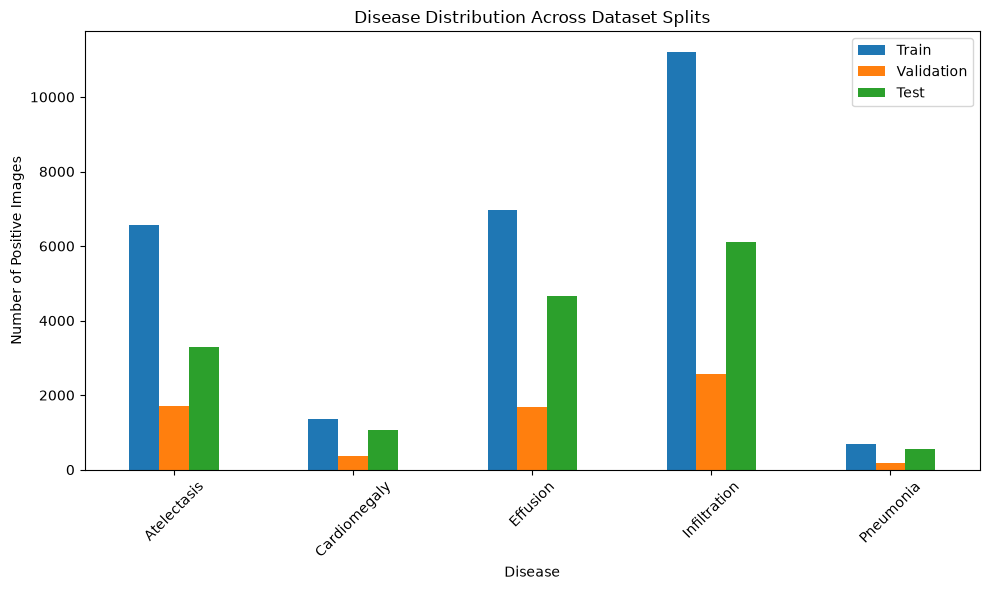

In [39]:
import matplotlib.pyplot as plt

distribution.plot(kind="bar", figsize=(10, 6))

plt.xlabel("Disease")
plt.ylabel("Number of Positive Images")
plt.title("Disease Distribution Across Dataset Splits")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Check clinical metadata

In [40]:
## Age

print("Train age statistics:")
print(train_df["Patient Age"].describe())

print("\nValidation age statistics:")
print(val_df["Patient Age"].describe())

print("\nTest age statistics:")
print(test_df["Patient Age"].describe())

Train age statistics:
count    69625.000000
mean        46.598276
std         16.699024
min          0.000000
25%         34.000000
50%         48.000000
75%         59.000000
max         95.000000
Name: Patient Age, dtype: float64

Validation age statistics:
count    16899.000000
mean        46.600036
std         16.551597
min          0.000000
25%         34.000000
50%         49.000000
75%         59.000000
max         93.000000
Name: Patient Age, dtype: float64

Test age statistics:
count    25596.000000
mean        46.720152
std         16.372221
min          0.000000
25%         34.000000
50%         49.000000
75%         59.000000
max         92.000000
Name: Patient Age, dtype: float64


In [41]:
## Sex

print("Train:")
print(train_df["Patient Sex"].value_counts(dropna=False))

print("\nValidation:")
print(val_df["Patient Sex"].value_counts(dropna=False))

print("\nTest:")
print(test_df["Patient Sex"].value_counts(dropna=False))

Train:
Patient Sex
M    39366
F    30259
Name: count, dtype: int64

Validation:
Patient Sex
M    9092
F    7807
Name: count, dtype: int64

Test:
Patient Sex
M    14882
F    10714
Name: count, dtype: int64


In [42]:
## View Position

print("Train:")
print(train_df["View Position"].value_counts(dropna=False))

print("\nValidation:")
print(val_df["View Position"].value_counts(dropna=False))

print("\nTest:")
print(test_df["View Position"].value_counts(dropna=False))

Train:
View Position
PA    45104
AP    24521
Name: count, dtype: int64

Validation:
View Position
PA    11110
AP     5789
Name: count, dtype: int64

Test:
View Position
AP    14500
PA    11096
Name: count, dtype: int64


Check whether images are available

In [43]:
RAW_DIR = "../data/raw/NIH_ChestXray14"

print(os.listdir(RAW_DIR))

['Data_Entry_2017_v2020.csv', 'test_list.txt', 'train_val_list.txt']


In [44]:
for root, dirs, files in os.walk(RAW_DIR):
    print(root, "->", len(files), "files")
    
    if len(files) > 0:
        print("Example files:", files[:5])

../data/raw/NIH_ChestXray14 -> 3 files
Example files: ['Data_Entry_2017_v2020.csv', 'test_list.txt', 'train_val_list.txt']


Find the image directory

In [46]:
import os

RAW_DIR = "../data/raw/NIH_ChestXray14"

print("Dataset directory:")
print(os.path.abspath(RAW_DIR))

print("\nContents:")
for item in os.listdir(RAW_DIR):
    print(item)

Dataset directory:
c:\Users\jinal\OneDrive\DL Project\AdaptiveMultimodalDL\data\raw\NIH_ChestXray14

Contents:
Data_Entry_2017_v2020.csv
test_list.txt
train_val_list.txt


In [48]:
import os

IMAGE_ROOT = "../data/raw/NIH_ChestXray14/images"

os.makedirs(IMAGE_ROOT, exist_ok=True)

print("Image folder created:")
print(os.path.abspath(IMAGE_ROOT))

Image folder created:
c:\Users\jinal\OneDrive\DL Project\AdaptiveMultimodalDL\data\raw\NIH_ChestXray14\images


In [49]:
all_required_images = set(
    train_df["Image Index"]
).union(
    set(val_df["Image Index"])
).union(
    set(test_df["Image Index"])
)

print("Total unique images required:", len(all_required_images))

Total unique images required: 112120


In [50]:
print("Example required images:")

for image_name in list(all_required_images)[:20]:
    print(image_name)

Example required images:
00000798_021.png
00010683_007.png
00010475_041.png
00000499_010.png
00009321_015.png
00025395_002.png
00030786_005.png
00007987_000.png
00013342_008.png
00002201_007.png
00018228_000.png
00013218_000.png
00027776_000.png
00014294_009.png
00027100_000.png
00001029_016.png
00021894_000.png
00010585_027.png
00002048_000.png
00015423_003.png


In [1]:
import os

RAW_DIR = "../data/raw/NIH_ChestXray14"

image_files = []

for root, dirs, files in os.walk(RAW_DIR):
    for file in files:
        if file.lower().endswith(".png"):
            image_files.append(os.path.join(root, file))

print("Total PNG images found:", len(image_files))

print("\nFirst 10 images:")
for path in image_files[:10]:
    print(path)

Total PNG images found: 84942

First 10 images:
../data/raw/NIH_ChestXray14\images\00000001_000.png
../data/raw/NIH_ChestXray14\images\00000001_001.png
../data/raw/NIH_ChestXray14\images\00000001_002.png
../data/raw/NIH_ChestXray14\images\00000002_000.png
../data/raw/NIH_ChestXray14\images\00000003_000.png
../data/raw/NIH_ChestXray14\images\00000003_001.png
../data/raw/NIH_ChestXray14\images\00000003_002.png
../data/raw/NIH_ChestXray14\images\00000003_003.png
../data/raw/NIH_ChestXray14\images\00000003_004.png
../data/raw/NIH_ChestXray14\images\00000003_005.png


In [ ]:
required_images = set(train_df["Image Index"]) | \
                  set(val_df["Image Index"]) | \
                  set(test_df["Image Index"])

found_image_names = {
    os.path.basename(path)
    for path in image_files
}

missing_images = required_images - found_image_names

print("Required images:", len(required_images))
print("Found images:", len(found_image_names))
print("Missing images:", len(missing_images))

In [ ]:
IMAGE_DIR = "../data/raw/NIH_ChestXray14/images"

print("Image directory:", os.path.abspath(IMAGE_DIR))

In [ ]:
from PIL import Image

test_image = os.path.join(
    IMAGE_DIR,
    train_df.iloc[0]["Image Index"]
)

image = Image.open(test_image)

print("Image:", train_df.iloc[0]["Image Index"])
print("Size:", image.size)
print("Mode:", image.mode)

Display an actual X-ray

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.title(train_df.iloc[0]["Finding Labels"])
plt.show()

Check the clinical features

In [ ]:
print(train_df["Patient Age"].describe())

print("\nSex:")
print(train_df["Patient Sex"].value_counts(dropna=False))

print("\nView Position:")
print(train_df["View Position"].value_counts(dropna=False))

In [ ]:
import pandas as pd
import numpy as np

def prepare_clinical_features(df):
    df = df.copy()

    # Convert age to numeric
    df["Patient Age"] = pd.to_numeric(
        df["Patient Age"], errors="coerce"
    )

    # Replace missing age with median age
    df["Patient Age"] = df["Patient Age"].fillna(
        df["Patient Age"].median()
    )

    # Encode sex
    df["Sex_Encoded"] = df["Patient Sex"].map({
        "M": 1.0,
        "F": 0.0
    })

    # Encode view position
    df["View_Encoded"] = df["View Position"].map({
        "PA": 1.0,
        "AP": 0.0
    })

    return df

In [ ]:
train_df = prepare_clinical_features(train_df)
val_df = prepare_clinical_features(val_df)
test_df = prepare_clinical_features(test_df)

print(train_df[[
    "Patient Age",
    "Sex_Encoded",
    "View_Encoded"
]].head())

Image transformations

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

Create the multimodal Dataset

In [ ]:
from PIL import Image
import os

TARGET_LABELS = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltration",
    "Pneumonia"
]

class MultimodalChestXrayDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image_name = row["Image Index"]
        image_path = os.path.join(
            self.image_dir,
            image_name
        )

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        clinical = torch.tensor([
            float(row["Patient Age"]),
            float(row["Sex_Encoded"]),
            float(row["View_Encoded"])
        ], dtype=torch.float32)

        labels = torch.tensor(
            row[TARGET_LABELS].values.astype(np.float32),
            dtype=torch.float32
        )

        return image, clinical, labels

Create Dataset objects

In [ ]:
IMAGE_DIR = "../data/raw/NIH_ChestXray14/images"

train_dataset = MultimodalChestXrayDataset(
    train_df,
    IMAGE_DIR,
    train_transform
)

val_dataset = MultimodalChestXrayDataset(
    val_df,
    IMAGE_DIR,
    eval_transform
)

test_dataset = MultimodalChestXrayDataset(
    test_df,
    IMAGE_DIR,
    eval_transform
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Test one sample

In [ ]:
image, clinical, labels = train_dataset[0]

print("Image shape:", image.shape)
print("Clinical:", clinical)
print("Labels:", labels)

Create DataLoaders

In [ ]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

In [ ]:
images, clinical, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Clinical:", clinical.shape)
print("Labels:", labels.shape)